In [26]:
%pip install gurobipy

In [27]:
# BOSTON FACILITY LOCATION OPTIMIZATION

import pandas as pd
import numpy as np
import geopandas as gpd
import gurobipy as gp

from gurobipy import GRB
from shapely.geometry import Point, MultiPoint
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt

# 1. IMPORT DATASETS

tourist_data = pd.read_csv("Boston_Attractions_Data.csv")
crime_data = pd.read_csv("BostonCrime1Yr_Nonviolent.csv")

# Display the first few rows
print("TOURIST DATA")
print(tourist_data.head())

print("\nCRIME DATA")
print(crime_data.head())

TOURIST DATA
   Attraction _ID                  Name        Lat       Long
0               1         Freedom Trail  42.363082 -71.056170
1               2         Quincy Market  42.360403 -71.054779
2               3  Boston Public Market  42.361815 -71.057580
3               4    North End District  42.363995 -71.054493
4               5   Museum of Fine Arts  42.339520 -71.094063

CRIME DATA
   NV_Incident_ID                                   Type  \
0               1  LARCENY THEFT FROM MV - NON-ACCESSORY   
1               2                 BURGLARY - RESIDENTIAL   
2               3                             AUTO THEFT   
3               4                              VANDALISM   
4               5                              VANDALISM   

                     Date                                             Street  \
0  2025-10-06 00:00:00+00                                      WASHINGTON ST   
1  2025-10-06 00:00:00+00                                      WASHINGTON ST   
2 

In [28]:
# 2. DEFINE COLUMN NAMES

tourist_lat_col = "Lat"
tourist_lon_col = "Long"

crime_lat_col = "Lat"
crime_lon_col = "Long"

# Optional tourist attraction importance
tourist_weight_col = None

# Optional crime severity
crime_weight_col = None

In [29]:
# 3. CLEAN DATA

tourist_data = tourist_data.dropna(
    subset=[tourist_lat_col, tourist_lon_col]
).copy()

crime_data = crime_data.dropna(
    subset=[crime_lat_col, crime_lon_col]
).copy()

# Convert coordinates to numeric
tourist_data[tourist_lat_col] = pd.to_numeric(
    tourist_data[tourist_lat_col], errors="coerce"
)

tourist_data[tourist_lon_col] = pd.to_numeric(
    tourist_data[tourist_lon_col], errors="coerce"
)

crime_data[crime_lat_col] = pd.to_numeric(
    crime_data[crime_lat_col], errors="coerce"
)

crime_data[crime_lon_col] = pd.to_numeric(
    crime_data[crime_lon_col], errors="coerce"
)

# Remove invalid coordinates
tourist_data = tourist_data.dropna(
    subset=[tourist_lat_col, tourist_lon_col]
)

crime_data = crime_data.dropna(
    subset=[crime_lat_col, crime_lon_col]
)

# Convert to arrays
tourist_coordinates = tourist_data[
    [tourist_lon_col, tourist_lat_col]
].to_numpy()

crime_coordinates = crime_data[
    [crime_lon_col, crime_lat_col]
].to_numpy()

print("Number of tourist attractions:", len(tourist_data))
print("Number of crime incidents:", len(crime_data))

Number of tourist attractions: 30
Number of crime incidents: 10485


In [30]:
# 4. GENERATE CANDIDATE LOCATIONS

# Coordinate reference system:
# EPSG:26986 = Massachusetts State Plane Mainland
# Units are meters

# CONVERT TOURIST AND CRIME DATA TO PROJECTED COORDINATES

tourist_gdf = gpd.GeoDataFrame(
    tourist_data.copy(),
    geometry=gpd.points_from_xy(
        tourist_data[tourist_lon_col],
        tourist_data[tourist_lat_col]
    ),
    crs="EPSG:4326"
).to_crs("EPSG:26986")

crime_gdf = gpd.GeoDataFrame(
    crime_data.copy(),
    geometry=gpd.points_from_xy(
        crime_data[crime_lon_col],
        crime_data[crime_lat_col]
    ),
    crs="EPSG:4326"
).to_crs("EPSG:26986")

# EXTRACT PROJECTED COORDINATES

tourist_xy = np.column_stack([
    tourist_gdf.geometry.x,
    tourist_gdf.geometry.y
])

crime_xy = np.column_stack([
    crime_gdf.geometry.x,
    crime_gdf.geometry.y
])

# COMBINE ALL KNOWN COORDINATES

all_coordinates = np.vstack([
    tourist_xy,
    crime_xy
])

# GENERATE APPROXIMATE STUDY AREA

study_area = MultiPoint(
    all_coordinates.tolist()
).convex_hull.buffer(250)

# GENERATE CANDIDATE GRID

# Grid spacing in meters
grid_spacing = 250

min_x, min_y, max_x, max_y = study_area.bounds

x_coords = np.arange(
    min_x,
    max_x + grid_spacing,
    grid_spacing
)

y_coords = np.arange(
    min_y,
    max_y + grid_spacing,
    grid_spacing
)

# Generate candidate points
candidate_points = []

for x in x_coords:
    for y in y_coords:

        point = Point(x, y)

        if study_area.covers(point):
            candidate_points.append(point)

# CREATE CANDIDATE LOCATIONS GEODATAFRAME

candidate_locations = gpd.GeoDataFrame(
    geometry=candidate_points,
    crs="EPSG:26986"
)

# LIMIT CANDIDATES FOR RESTRICTED GUROBI LICENSE

max_candidates = 10

if len(candidate_locations) > max_candidates:

    selected_indices = np.linspace(
        0,
        len(candidate_locations) - 1,
        max_candidates,
        dtype=int
    )

    candidate_locations = candidate_locations.iloc[
        selected_indices
    ].copy()

# Assign sequential candidate IDs
candidate_locations = candidate_locations.reset_index(drop=True)

candidate_locations["Candidate_ID"] = range(
    len(candidate_locations)
)

# EXTRACT CANDIDATE COORDINATES

candidate_xy = np.column_stack([
    candidate_locations.geometry.x,
    candidate_locations.geometry.y
])

# DISPLAY RESULTS

print("Number of tourist locations:", len(tourist_data))
print("Number of crime locations:", len(crime_data))
print("Number of candidate locations:", len(candidate_locations))

display(candidate_locations)


Number of tourist locations: 30
Number of crime locations: 10485
Number of candidate locations: 10


,geometry,Candidate_ID
0,POINT (17363.793 712773.779),0
1,POINT (86363.793 770773.779),1
2,POINT (117113.793 797273.779),2
3,POINT (140613.793 825273.779),3
4,POINT (160613.793 838273.779),4
5,POINT (178113.793 858273.779),5
6,POINT (194113.793 862773.779),6
7,POINT (208613.793 884273.779),7
8,POINT (223113.793 899023.779),8
9,POINT (244863.793 898023.779),9


In [31]:
# 5. FIND NEAREST CANDIDATE LOCATIONS

# Number of nearest candidate locations to consider
K = 10

# Store the nearest candidate locations for each tourist attraction
nearest_candidates = {}

for i in range(len(tourist_data)):

    nearest_candidates[i] = np.argsort(
        tourist_distance[i]
    )[:min(K, len(candidate_locations))].tolist()

print("Nearest candidate locations calculated!")

# Display the first tourist attraction's nearest candidates
print("Nearest candidates for tourist location 0:",
      nearest_candidates[0])


Nearest candidate locations calculated!
Nearest candidates for tourist location 0: [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]


In [32]:
# 6. BUILD GUROBI MODEL

model = gp.Model("Boston_Accommodation_Location")

# SETS

J = range(len(candidate_locations))
I = range(len(tourist_data))

total_facilities = 3

# DECISION VARIABLES

# x[j] = 1 if an accommodation location is selected
x = model.addVars(
    J,
    vtype=GRB.BINARY,
    name="Accommodation"
)

# y[i,j] = 1 if tourist attraction i is assigned to location j
y = model.addVars(
    [(i, j) for i in I for j in nearest_candidates[i]],
    vtype=GRB.BINARY,
    name="Assignment"
)

# CONSTRAINT 1: SELECT EXACTLY 3 LOCATIONS

model.addConstr(
    gp.quicksum(x[j] for j in J) == total_facilities,
    name="Total_Accommodation_Locations"
)

# CONSTRAINT 2: ASSIGN EACH TOURIST ATTRACTION
# TO EXACTLY ONE LOCATION

for i in I:

    model.addConstr(
        gp.quicksum(
            y[i, j] for j in nearest_candidates[i]
        ) == 1,
        name=f"Tourist_Assignment_{i}"
    )

# CONSTRAINT 3: ASSIGNMENT ONLY TO SELECTED
# ACCOMMODATION LOCATIONS

for i in I:
    for j in nearest_candidates[i]:

        model.addConstr(
            y[i, j] <= x[j],
            name=f"Assignment_Link_{i}_{j}"
        )

# 7. OBJECTIVE FUNCTIONS

# TOURIST IMPORTANCE WEIGHTS

if tourist_weight_col is not None:

    tourist_weights = pd.to_numeric(
        tourist_data[tourist_weight_col],
        errors="coerce"
    ).fillna(1).to_numpy()

else:

    tourist_weights = np.ones(len(tourist_data))

# OBJECTIVE 1:
# MINIMIZE DISTANCE TO TOURIST ATTRACTIONS

tourist_objective = gp.quicksum(
    tourist_weights[i] *
    tourist_distance[i, j] *
    y[i, j]

    for i in I
    for j in nearest_candidates[i]
)

# OBJECTIVE 2:
# MINIMIZE CRIME EXPOSURE

crime_objective = gp.quicksum(
    crime_risk[j] * x[j]

    for j in J
)

# 8. HIERARCHICAL MULTI-OBJECTIVE OPTIMIZATION

# Both objectives are minimization objectives.

model.ModelSense = GRB.MINIMIZE

# Priority 2: Tourist accessibility
model.setObjectiveN(
    tourist_objective,
    index=0,
    priority=2,
    weight=1.0,
    abstol=0.0,
    reltol=0.0,
    name="Tourist_Accessibility"
)

# Priority 1: Crime avoidance
model.setObjectiveN(
    crime_objective,
    index=1,
    priority=1,
    weight=1.0,
    abstol=0.0,
    reltol=0.0,
    name="Crime_Avoidance"
)

# Solver settings
model.Params.MIPGap = 0.01

# Display model size
model.update()

print("Decision variables:", model.NumVars)
print("Constraints:", model.NumConstrs)

# 9. SOLVE MODEL

model.optimize()

if model.Status == GRB.OPTIMAL:

    print("\nOPTIMAL SOLUTION FOUND!")

    # Calculate objective values directly
    print(
        "Tourist accessibility objective:",
        tourist_objective.getValue()
    )

    print(
        "Crime avoidance objective:",
        crime_objective.getValue()
    )

elif model.SolCount > 0:

    print("\nA FEASIBLE SOLUTION WAS FOUND.")

    print(
        "Tourist accessibility objective:",
        tourist_objective.getValue()
    )

    print(
        "Crime avoidance objective:",
        crime_objective.getValue()
    )

else:

    print("\nNo feasible solution was found.")



Set parameter MIPGap to value 0.01
Decision variables: 310
Constraints: 331
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Non-default parameters:
MIPGap  0.01

Optimize a model with 331 rows, 310 columns and 910 nonzeros (Min)
Model fingerprint: 0x8c58f160
Model has 300 linear objective coefficients
Variable types: 0 continuous, 310 integer (310 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [3e-114, 3e+05]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]


---------------------------------------------------------------------------
Multi-objectives: starting optimization (min) with 2 objectives... 
---------------------------------------------------------------------------

Multi-objectives: applying initial presolve...
------------------------

In [33]:
# 10. EXTRACT RECOMMENDED LOCATIONS

selected_locations = []

if model.SolCount > 0:

    for j in J:

        if x[j].X > 0.5:

            selected_locations.append({
                "Candidate_ID": candidate_locations.iloc[j]["Candidate_ID"],
                "Crime_Risk": crime_risk[j],
                "Easting": candidate_locations.geometry.iloc[j].x,
                "Northing": candidate_locations.geometry.iloc[j].y
            })

    selected_locations_df = pd.DataFrame(selected_locations)

    print("\nTHREE RECOMMENDED ACCOMMODATION LOCATIONS:")
    display(selected_locations_df)

else:
    print("No solution available to extract.")



THREE RECOMMENDED ACCOMMODATION LOCATIONS:


,Candidate_ID,Crime_Risk,Easting,Northing
0,1,5.086012e-79,86363.792933,770773.779341
1,8,7.579285e-03,223113.792933,899023.779341
2,9,2.894527e-04,244863.792933,898023.779341


In [34]:
# 11. CONVERT RECOMMENDED LOCATIONS TO LATITUDE/LONGITUDE
selected_gdf = gpd.GeoDataFrame(
    selected_locations_df,
    geometry=gpd.points_from_xy(
        selected_locations_df["Easting"],
        selected_locations_df["Northing"]
    ),
    crs="EPSG:26986"
)

selected_gdf = selected_gdf.to_crs("EPSG:4326")

selected_locations_df["Longitude"] = selected_gdf.geometry.x
selected_locations_df["Latitude"] = selected_gdf.geometry.y

print("\nFINAL RECOMMENDED LOCATIONS:")
display(
    selected_locations_df[
        ["Candidate_ID", "Latitude", "Longitude", "Crime_Risk"]
    ]
)



FINAL RECOMMENDED LOCATIONS:


,Candidate_ID,Latitude,Longitude,Crime_Risk
0,1,41.178907,-72.854199,5.086012e-79
1,8,42.341366,-71.219505,7.579285e-03
2,9,42.331416,-70.955644,2.894527e-04


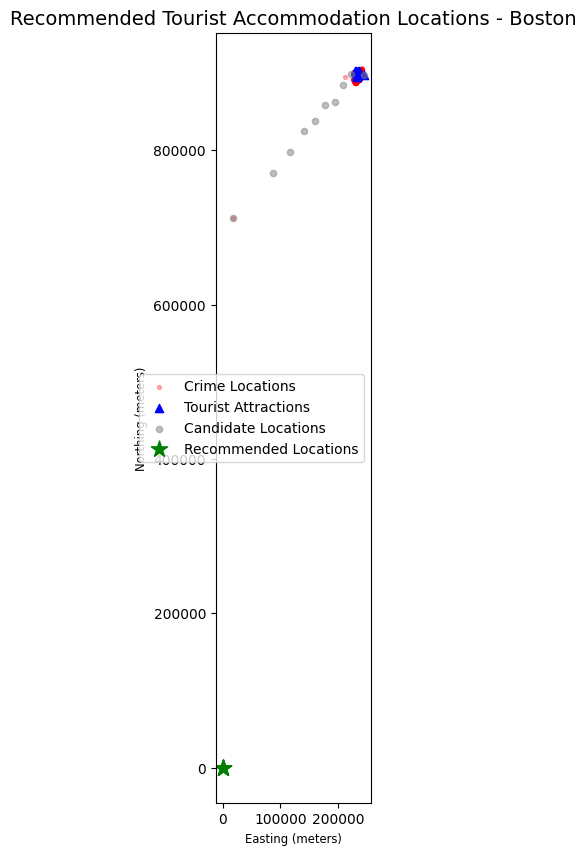

In [35]:
# 12. VISUALIZE RECOMMENDED LOCATIONS

fig, ax = plt.subplots(figsize=(12, 10))

# Crime locations
crime_gdf.plot(
    ax=ax,
    color="red",
    markersize=8,
    alpha=0.3,
    label="Crime Locations"
)

# Tourist attractions
tourist_gdf.plot(
    ax=ax,
    color="blue",
    markersize=35,
    marker="^",
    label="Tourist Attractions"
)

# All candidate locations
candidate_locations.plot(
    ax=ax,
    color="gray",
    markersize=20,
    alpha=0.5,
    label="Candidate Locations"
)

# Selected accommodation locations
selected_gdf.plot(
    ax=ax,
    color="green",
    markersize=150,
    marker="*",
    label="Recommended Locations"
)

ax.set_title(
    "Recommended Tourist Accommodation Locations - Boston",
    fontsize=14
)

ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")

ax.legend()
plt.show()


In [36]:
selected_locations_df.to_csv(
    "boston_recommended_accommodation_locations.csv",
    index=False
)

print("Results successfully saved!")

Results successfully saved!
